In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/neha2611/sleep-apnea/a01.txt
/kaggle/input/datasets/neha2611/sleep-apnea/a01.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/neha2611/sleep-apnea/a01.csv')
df.columns=['Time','ECG']
df.head()

,Time,ECG
0,'0:00.010',-0.065
1,'0:00.020',-0.060
2,'0:00.030',-0.075
3,'0:00.040',-0.065
4,'0:00.050',-0.070


In [3]:
# Total number of ECG samples
print("Total ECG Samples:", len(df))

# First 10 ECG values
print("\nFirst 10 ECG Values:")
print(df['ECG'].head(10))

# Basic statistics
print("\nStatistics:")
print(df['ECG'].describe())

Total ECG Samples: 2956999

First 10 ECG Values:
0   -0.065
1   -0.060
2   -0.075
3   -0.065
4   -0.070
5   -0.070
6   -0.090
7   -0.080
8   -0.095
9   -0.080
Name: ECG, dtype: float64

Statistics:
count    2.956999e+06
mean     5.639484e-04
std      2.444641e-01
min     -1.655000e+00
25%     -8.000000e-02
50%     -3.000000e-02
75%      4.500000e-02
max      2.440000e+00
Name: ECG, dtype: float64


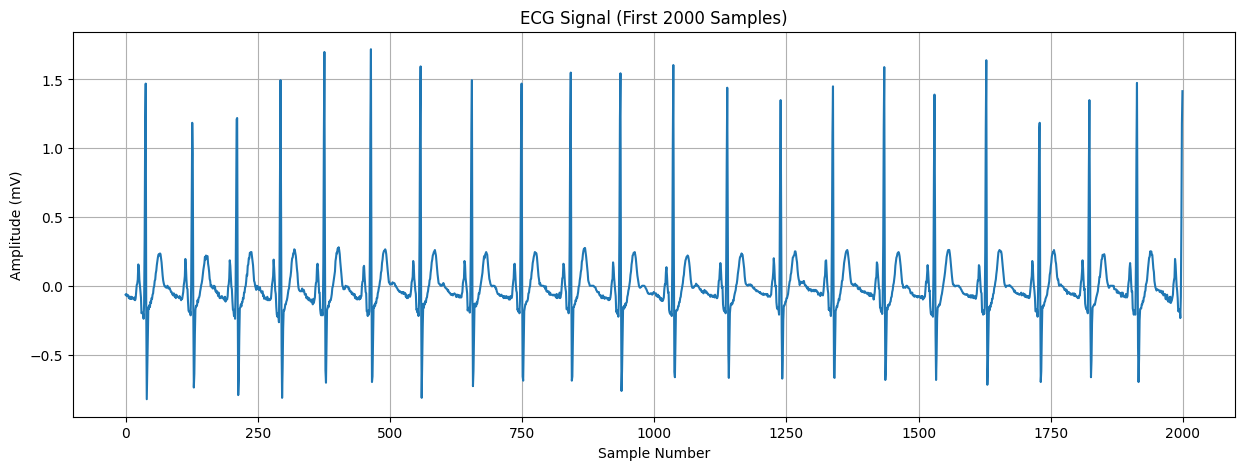

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))

plt.plot(df['ECG'][:2000])

plt.title("ECG Signal (First 2000 Samples)")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude (mV)")

plt.grid(True)
plt.show()

In [5]:
# Display the first 10 time values
print(df['Time'].head(10))

0    '0:00.010'
1    '0:00.020'
2    '0:00.030'
3    '0:00.040'
4    '0:00.050'
5    '0:00.060'
6    '0:00.070'
7    '0:00.080'
8    '0:00.090'
9    '0:00.100'
Name: Time, dtype: object


In [6]:
# Sampling frequency(HZ)
fs = 100 # for 1 sec 100 samples

# Window duration (60 seconds)
window_duration = 60

# Number of samples in one window
window_size = fs * window_duration

print("Window Size:", window_size)

# Convert ECG column to NumPy array
ecg_signal = df['ECG'].values

# Split into 60-second windows
windows = []

for i in range(0, len(ecg_signal), window_size):
    window = ecg_signal[i:i + window_size]

    # Keep only complete windows
    if len(window) == window_size:
        windows.append(window)

windows = np.array(windows)

print("Shape of windows:", windows.shape)
print("First window shape:", windows[0].shape)

Window Size: 6000
Shape of windows: (492, 6000)
First window shape: (6000,)


In [7]:
from scipy.signal import find_peaks
# Take the first 60-second ECG window
first_window = windows[0]

# Detect peaks
peaks, properties = find_peaks(
    first_window,
    distance=60,
    prominence=0.5
)

print("Number of R-peaks:", len(peaks))
print("\nFirst 10 peak indices:")
print(peaks[:10])

Number of R-peaks: 67

First 10 peak indices:
[ 38 126 211 293 376 464 558 655 749 842]


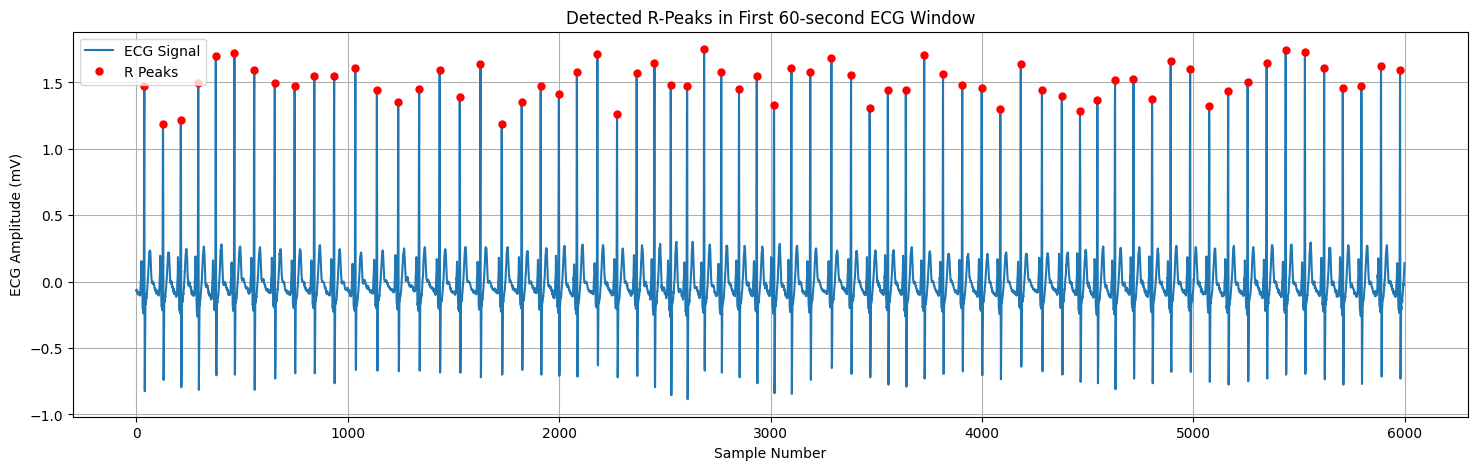

In [8]:
plt.figure(figsize=(18,5))

# Plot ECG signal
plt.plot(first_window, label='ECG Signal')

# Plot detected R-peaks
plt.plot(peaks, first_window[peaks], 'ro', markersize=5, label='R Peaks')

plt.title("Detected R-Peaks in First 60-second ECG Window")
plt.xlabel("Sample Number")
plt.ylabel("ECG Amplitude (mV)")
plt.legend()
plt.grid(True)

plt.show()

In [9]:
# Difference between consecutive R-peaks
rr_intervals = np.diff(peaks)

print("First 10 RR intervals (in samples):")
print(rr_intervals[:10])

print("\nTotal RR intervals:", len(rr_intervals))

First 10 RR intervals (in samples):
[88 85 82 83 88 94 97 94 93 94]

Total RR intervals: 66


In [10]:
rr_seconds = rr_intervals / fs

print("First 10 RR intervals (seconds):")
print(rr_seconds[:10])

First 10 RR intervals (seconds):
[0.88 0.85 0.82 0.83 0.88 0.94 0.97 0.94 0.93 0.94]


In [11]:
from scipy.stats import kurtosis, skew

# Extract features from one RR interval sequence
features = [
    np.max(rr_seconds),
    np.min(rr_seconds),
    np.mean(rr_seconds),
    np.median(rr_seconds),
    np.std(rr_seconds),
    kurtosis(rr_seconds),
    skew(rr_seconds)
]

feature_names = [
    "Maximum",
    "Minimum",
    "Mean",
    "Median",
    "Standard Deviation",
    "Kurtosis",
    "Skewness"
]

for name, value in zip(feature_names, features):
    print(f"{name}: {value:.4f}")

Maximum: 1.0200
Minimum: 0.7700
Mean: 0.9000
Median: 0.9000
Standard Deviation: 0.0592
Kurtosis: -0.5778
Skewness: 0.0706


In [12]:
from scipy.signal import find_peaks
from scipy.stats import kurtosis, skew

X = []

for window in windows:

    # Detect R-peaks
    peaks, _ = find_peaks(
        window,
        distance=60,
        prominence=0.5
    )

    # Need at least two peaks
    if len(peaks) < 2:
        continue

    # RR intervals
    rr = np.diff(peaks) / fs

    # Extract statistical features
    features = [
        np.max(rr),
        np.min(rr),
        np.mean(rr),
        np.median(rr),
        np.std(rr),
        kurtosis(rr),
        skew(rr)
    ]

    X.append(features)

X = np.array(X)

print("Feature Matrix Shape:", X.shape)

Feature Matrix Shape: (492, 7)


In [13]:
df1 = pd.read_csv(
    '/kaggle/input/datasets/neha2611/sleep-apnea/a01.txt',
    delimiter='\s+',
    index_col=False
)
df1Arr = df1.loc[:, 'N']

<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_16/1717229083.py:3: SyntaxWarning: invalid escape sequence '\s'
  delimiter='\s+',


In [14]:

print(df1.head())

print("\nColumns:")
print(df1.columns)

print("\nShape:")
print(df1.shape)

print("\nUnique Labels:")
print(df1Arr.unique())

   0:00.000      0  N  0.1  0.2  0.3
0  1:00.000   6000  N    0    0    0
1  2:00.000  12000  N    0    0    0
2  3:00.000  18000  N    0    0    0
3  4:00.000  24000  N    0    0    0
4  5:00.000  30000  N    0    0    0

Columns:
Index(['0:00.000', '0', 'N', '0.1', '0.2', '0.3'], dtype='object')

Shape:
(488, 6)

Unique Labels:
['N' 'A']


In [15]:
df1.columns = [
    "Time",
    "Sample",
    "Label",
    "Col4",
    "Col5",
    "Col6"
]

print(df1.head())

       Time  Sample Label  Col4  Col5  Col6
0  1:00.000    6000     N     0     0     0
1  2:00.000   12000     N     0     0     0
2  3:00.000   18000     N     0     0     0
3  4:00.000   24000     N     0     0     0
4  5:00.000   30000     N     0     0     0


In [16]:
# Convert labels to binary
y = df1['Label'].map({
    'N': 0,
    'A': 1
})

print(y.head())
print("\nNumber of labels:", len(y))
print("\nClass Distribution:")
print(y.value_counts())

0    0
1    0
2    0
3    0
4    0
Name: Label, dtype: int64

Number of labels: 488

Class Distribution:
Label
1    470
0     18
Name: count, dtype: int64


In [17]:
min_len = min(len(X), len(y))

X = X[:min_len]
y = y[:min_len]

In [18]:
#Sometimes the number of ECG windows and labels differ slightly.
print("Before Alignment")
print("X Shape:", X.shape)
print("y Shape:", y.shape)

min_len = min(len(X), len(y))

X = X[:min_len]
y = y[:min_len]

print("\nAfter Alignment")
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Before Alignment
X Shape: (488, 7)
y Shape: (488,)

After Alignment
X Shape: (488, 7)
y Shape: (488,)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.6651899   0.48987084 -1.30602244 -1.37605547 -1.70393283 -0.08270647
   0.66440561]
 [-2.23881572 -0.52925144 -2.14181838 -2.08659077 -2.00390145  0.93678044
  -0.2861987 ]
 [-1.88029958 -0.96601814 -2.51099695 -2.56028097 -1.2211251  -0.57380875
   0.69988021]
 [-2.95584799 -1.98514042 -3.3775712  -3.03397117 -1.66969694  0.17068645
  -0.74116589]
 [-2.38222217 -0.67484034 -2.74252642 -2.67870352 -1.99305081  0.70778308
   1.06530717]]


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X_scaled,

    y,

    test_size=0.2,

    random_state=42,

    stratify=y

)

print(X_train.shape)
print(X_test.shape)

(390, 7)
(98, 7)


In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense, Dropout

model = Sequential()

model.add(Dense(40, activation='relu', input_shape=(7,)))

model.add(Dropout(0.2))

model.add(Dense(20, activation='relu'))

model.add(Dropout(0.2))

model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-07-14 21:37:03.993820: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [22]:
model.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=['accuracy']

)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 40)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │           820 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,161 (4.54 KB)

 Trainable params: 1,161 (4.54 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
from tensorflow.keras.callbacks import EarlyStopping
call=EarlyStopping(monitor='val_loss',mode='min',verbose=1,patience=25)

In [24]:
history = model.fit(

    X_train,

    y_train,

    epochs=200,

    batch_size=32,

    validation_split=0.2,

    verbose=1,

    callbacks=[call]

)

Epoch 1/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.1538 - loss: 0.9022 - val_accuracy: 0.1282 - val_loss: 0.8054
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4295 - loss: 0.7560 - val_accuracy: 0.7821 - val_loss: 0.6736
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6763 - loss: 0.6564 - val_accuracy: 0.8974 - val_loss: 0.5813
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8429 - loss: 0.5818 - val_accuracy: 0.9359 - val_loss: 0.5061
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9327 - loss: 0.5021 - val_accuracy: 0.9615 - val_loss: 0.4461
Epoch 6/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9519 - loss: 0.4704 - val_accuracy: 0.9615 - val_loss: 0.3959
Epoch 7/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9583 - loss: 0.4149 - val_accuracy: 0.9615 - val_loss: 0.3563
Epoch 8/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9615 - loss: 0.3649 - val_accuracy: 0.9615 

In [25]:
loss, accuracy = model.evaluate(

    X_test,

    y_test,

    verbose=0

)

print("Test Accuracy:", accuracy)

Test Accuracy: 0.9795918464660645


In [26]:
y_prob = model.predict(X_test)

y_pred = (y_prob > 0.5).astype(int)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


In [27]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(

    y_test,

    y_pred

)

print(cm)

[[ 2  2]
 [ 0 94]]


In [28]:
from sklearn.metrics import classification_report

print(

classification_report(

    y_test,

    y_pred

)

)

              precision    recall  f1-score   support

           0       1.00      0.50      0.67         4
           1       0.98      1.00      0.99        94

    accuracy                           0.98        98
   macro avg       0.99      0.75      0.83        98
weighted avg       0.98      0.98      0.98        98



In [29]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(

    y_test,

    y_prob

)

print("ROC AUC:", auc)

ROC AUC: 1.0


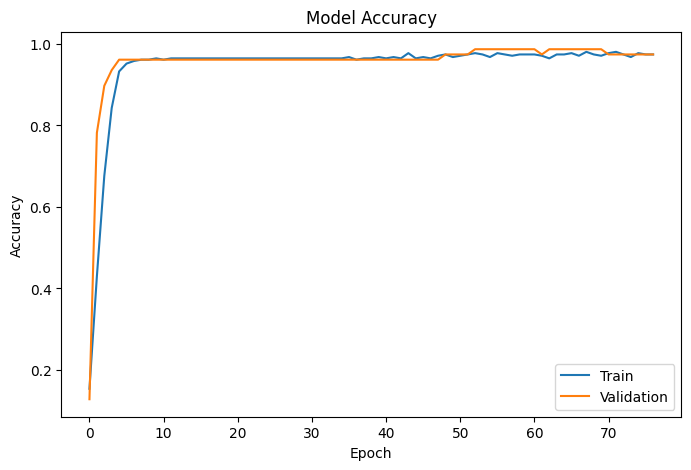

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Train')

plt.plot(history.history['val_accuracy'], label='Validation')

plt.title("Model Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

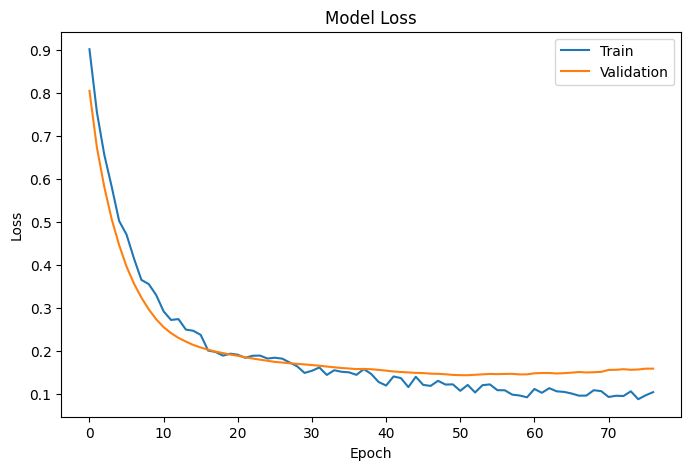

In [31]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Train')

plt.plot(history.history['val_loss'], label='Validation')

plt.title("Model Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [32]:
from tensorflow.keras.models import load_model
neural_net_model = model.save('SleepApnea-predictor.keras') # save model
